# 04 | Interpretación y análisis de errores
**Grupo 6 · Machine Learning · porcentaje de propina en taxis amarillos de NYC (ene-abr 2026)**

Analiza el modelo final (`hgb_absoluto`) en **validación (marzo completo)** y, al final, confirma los patrones en test (abril).
Las tablas se generan en `src/train.py`; aquí se leen y se interpretan. Además se usan los datos de enero para explicar dos
variables que resultaron muy importantes (`RatecodeID` y `VendorID`).

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT, FIG = ROOT / 'outputs', ROOT / 'reports' / 'figures'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
assert (OUT / 'metrics_validacion.json').exists(), 'Ejecuta antes: python main.py --data-dir Data'
val = json.loads((OUT / 'metrics_validacion.json').read_text(encoding='utf-8'))
test = json.loads((OUT / 'metrics_test.json').read_text(encoding='utf-8')) if (OUT / 'metrics_test.json').exists() else None
DATA_DIR = Path(os.environ.get('TAXI_DATA_DIR', ROOT / 'Data'))
seg = pd.read_csv(OUT / 'errores_por_segmento_validacion.csv')
def tabla(nombre, df=seg):
    return df[df.segmento == nombre].drop(columns='segmento').set_index('valor')

## 1. Interpretación global: importancia por permutación

Se permuta cada variable en 30 000 viajes de marzo y se mide cuánto sube el MAE (en pp). Se calcula sobre las variables antes del
preprocesamiento, así que se lee directamente.

,feature,importancia_media,desv
0,ratio_subtotal_fare,3.1651,0.0275
1,RatecodeID_cat,1.4890,0.0013
2,fare_amount,0.5046,0.0035
3,VendorID_cat,0.4508,0.0086
4,subtotal_pre_tip,0.1906,0.0011
5,extra,0.0987,0.0008
6,Airport_fee,0.0349,0.0005
7,improvement_surcharge,0.0269,0.0004
8,cbd_congestion_fee,0.0237,0.0005
9,hour_cos,0.0234,0.0002


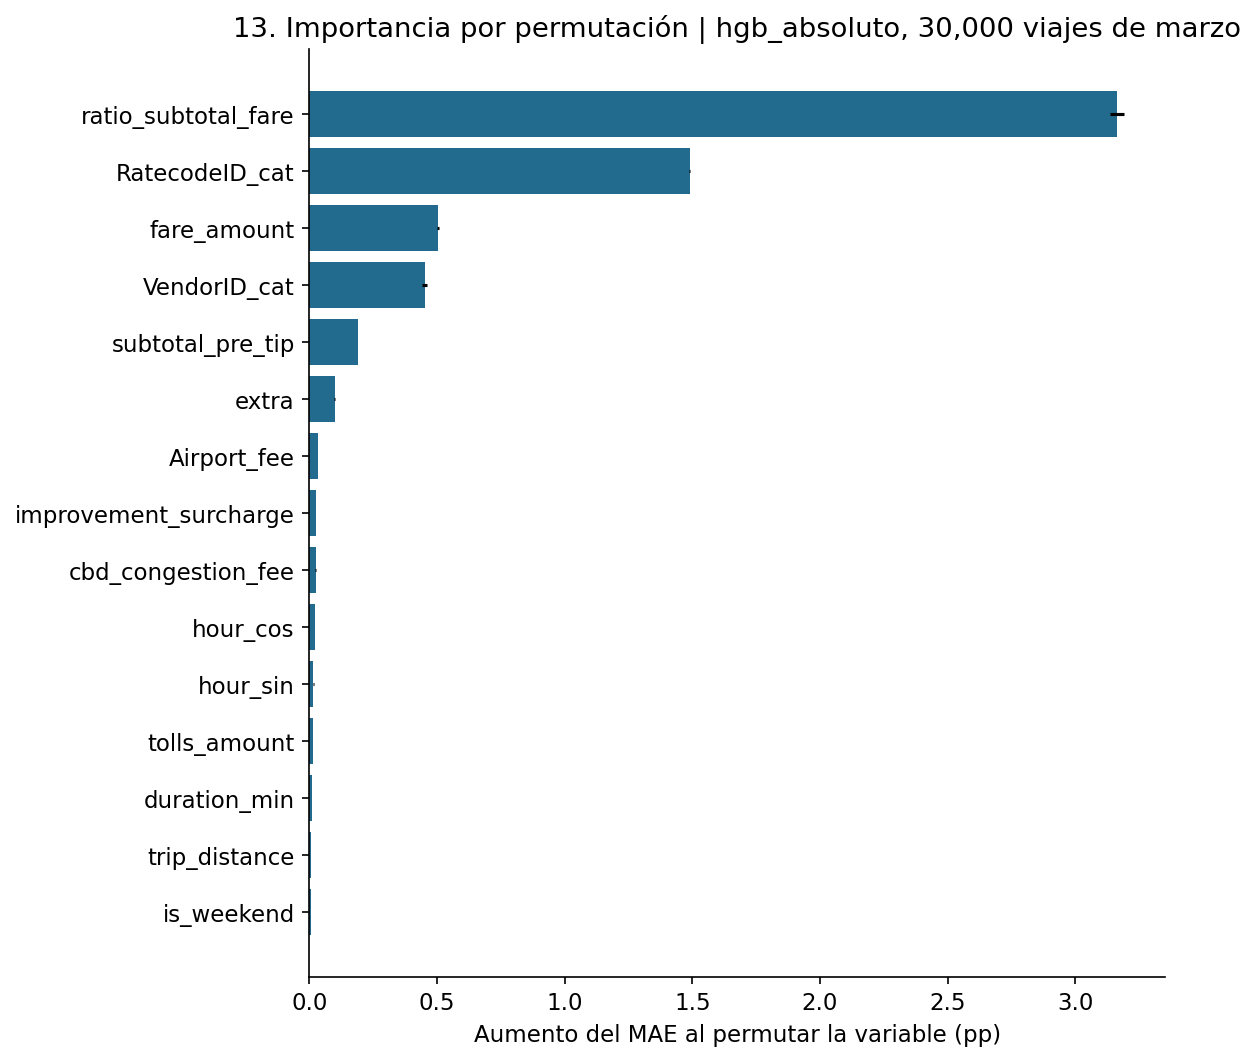

In [2]:
imp = pd.read_csv(OUT / 'importancia_variables.csv')
display(imp.head(15))
display(Image(filename=str(FIG / '13_importancia_permutacion.png')))

## 2. ¿Por qué pesan tanto `RatecodeID` y `VendorID`?

Se revisa con enero (entrenamiento), no con marzo.

In [3]:
from src.data import load_population
jan, _ = load_population(DATA_DIR, '2026-01')
jan['propina_cero'] = jan.tip_percentage.eq(0)
display(jan.groupby('RatecodeID').agg(n=('tip_percentage', 'size'), mediana=('tip_percentage', 'median'),
                                      pct_cero=('propina_cero', lambda s: round(100 * s.mean(), 1))))
display(jan.groupby('VendorID').agg(n=('tip_percentage', 'size'), mediana=('tip_percentage', 'median'),
                                    pct_cero=('propina_cero', lambda s: round(100 * s.mean(), 1))))
print('Faltantes de RatecodeID en la población con tarjeta:', jan.RatecodeID.isna().mean())
del jan

Faltantes de RatecodeID en la población con tarjeta: 0.0


,n,mediana,pct_cero
RatecodeID,,,
1.0,1990303,27.421875,4.5
2.0,68718,23.271429,4.9
3.0,7504,22.610446,9.0
4.0,5863,20.520291,15.1
5.0,27122,20.235294,18.6
99.0,110749,0.000000,100.0


,n,mediana,pct_cero
VendorID,,,
1,504456,25.536481,25.1
2,1705803,26.764706,4.9


- `RatecodeID = 99` (código "desconocido" en el diccionario) concentra viajes con propina cero: el modelo aprende que en esos
  registros casi nunca se anota propina.
- Los dos proveedores (`VendorID` 1 y 2) tienen tasas de propina cero muy distintas. Como el pasajero no elige el proveedor, la
  diferencia apunta a cómo cada sistema registra o presenta la propina, no a un comportamiento de los pasajeros. Es un
  **sesgo de medición**: el modelo funciona de manera distinta según la tecnología del taxi (sección 5).
- Los faltantes de `RatecodeID` y `passenger_count` (27.6% en los datos originales) están **todos fuera** de la población con
  tarjeta (pertenecen a `payment_type = 0`, Flex Fare). Por eso el segmento "RatecodeID faltante" de la tabla de errores tiene un
  único valor.

## 3. Dependencia parcial

Cómo cambia la predicción media al fijar una variable en distintos valores (5 000 viajes de marzo, el resto de variables sin cambios).

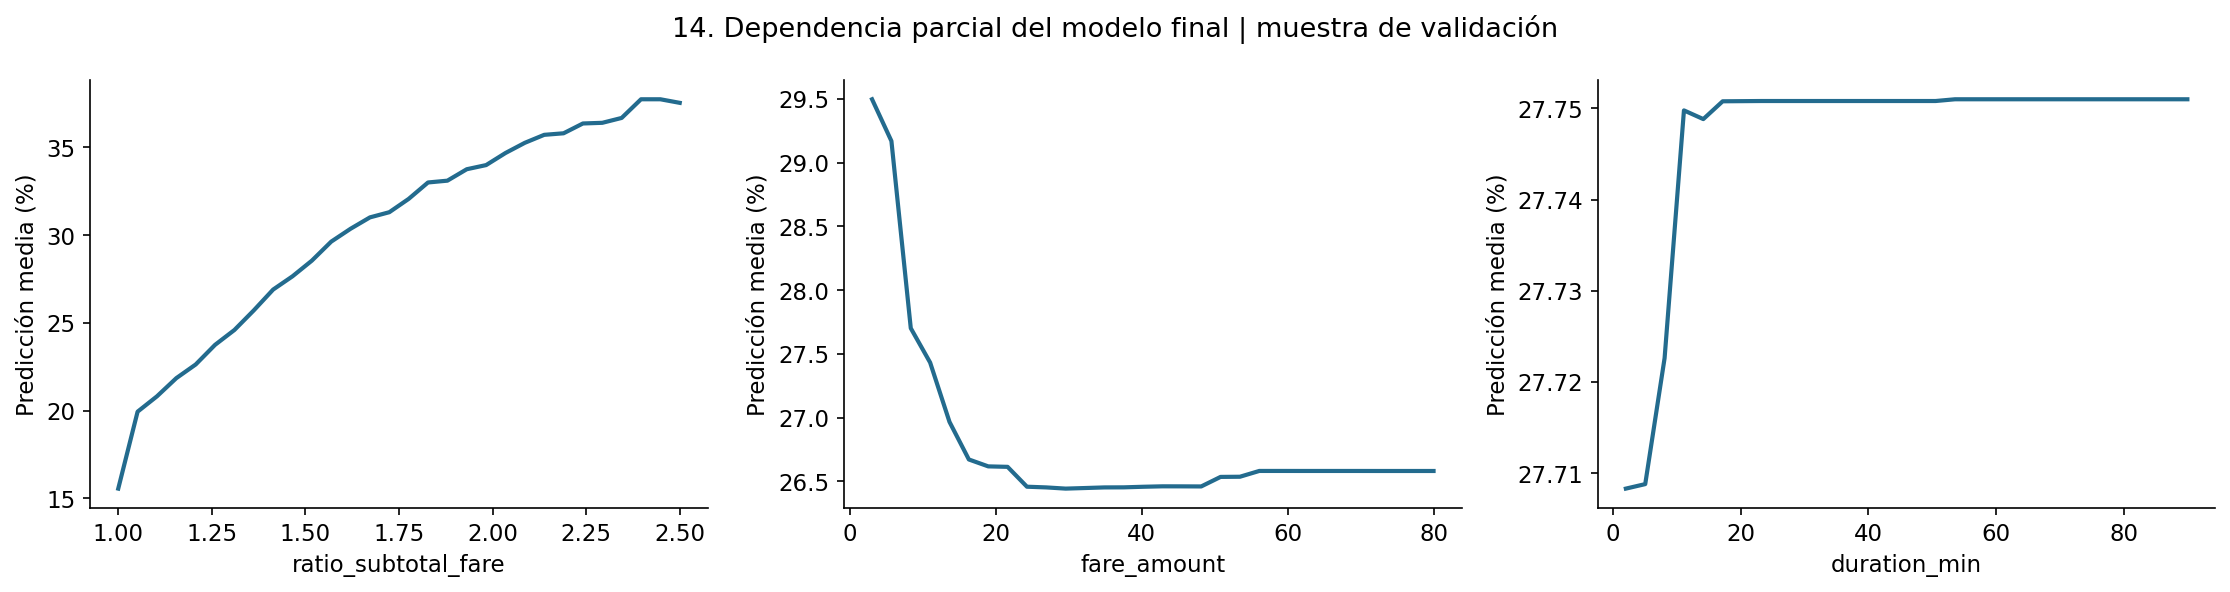

,min_pred,max_pred
variable,,
duration_min,27.71,27.75
fare_amount,26.44,29.50
ratio_subtotal_fare,15.56,37.74


In [4]:
display(Image(filename=str(FIG / '14_dependencia_parcial.png')))
pdp = pd.read_csv(OUT / 'dependencia_parcial.csv')
display(pdp.groupby('variable').agg(min_pred=('prediccion_media', 'min'), max_pred=('prediccion_media', 'max')).round(2))

La predicción crece con `subtotal / tarifa` (más recargos → el mismo botón equivale a más porcentaje de la tarifa) y cae con la
tarifa: en viajes caros los pasajeros dejan una proporción algo menor. La duración aporta poco una vez conocida la tarifa.

## 4. Errores por segmento (validación)

`sesgo_medio_pp` = promedio de (predicho − real): positivo significa sobreestimación. `mejora_pct` compara con el baseline lineal
en el mismo segmento.

In [5]:
for nombre in ['propina real', 'tarifa base (USD)', 'distancia (mi)', 'franja horaria', 'fin de semana', 'aeropuerto',
               'VendorID', 'registro sospechoso']:
    print('\n==', nombre)
    display(tabla(nombre))


== propina real

== tarifa base (USD)

== distancia (mi)

== franja horaria

== fin de semana

== aeropuerto

== VendorID

== registro sospechoso


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
cero,253733,9.89,0.00,13.115,0.000,13.115,12.508,-4.9
positiva,2311669,90.11,27.42,5.567,0.111,1.368,6.977,20.2


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
0-1,18,0.00,80.68,15958.327,96.488,-15885.376,15959.899,0.0
1-5,32262,1.26,45.45,30.450,7.275,-14.200,33.672,9.6
5-10,807850,31.49,32.26,7.263,0.097,2.923,8.356,13.1
10-20,982082,38.28,26.76,5.803,0.090,3.090,6.797,14.6
20-50,560467,21.85,23.14,4.425,0.069,2.320,6.002,26.3
50+,182723,7.12,21.36,4.820,0.233,2.946,6.227,22.6


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
0-1,643547,25.09,32.37,9.012,0.161,1.601,10.381,13.2
1-2,824715,32.15,28.19,6.064,0.075,3.068,7.031,13.8
2-5,640661,24.97,24.97,5.416,0.081,2.958,6.665,18.7
5-10,229633,8.95,22.78,4.409,0.124,2.294,5.900,25.3
10-20,200602,7.82,21.12,3.942,0.137,2.130,5.195,24.1
20+,26244,1.02,20.27,4.696,0.198,3.077,5.908,20.5


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
madrugada (0-5),180402,7.03,26.25,8.774,0.256,3.534,9.958,11.9
mañana pico (6-9),316785,12.35,25.24,5.743,0.103,2.324,6.678,14.0
día (10-15),839671,32.73,25.59,5.582,0.045,1.736,6.716,16.9
tarde pico (16-19),702163,27.37,27.88,6.702,0.120,3.059,8.124,17.5
noche (20-23),526381,20.52,27.06,6.465,0.133,2.871,7.687,15.9


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
no,1890978,73.71,26.51,6.169,0.093,2.419,7.394,16.6
sí,674424,26.29,26.25,6.721,0.139,2.840,7.888,14.8


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
desde aeropuerto,191253,7.46,23.36,5.465,0.539,2.610,6.971,21.6
hacia aeropuerto,46919,1.83,23.84,5.276,0.297,2.409,6.477,18.5
sin aeropuerto,2327230,90.72,26.84,6.405,0.067,2.526,7.590,15.6


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
1,580676,22.63,25.32,5.307,0.097,0.873,6.449,17.7
2,1984726,77.37,26.69,6.609,0.107,3.015,7.838,15.7


,n,pct_viajes,mediana_real_pp,MAE_pp,MedAE_pp,sesgo_medio_pp,MAE_baseline_pp,mejora_pct
valor,,,,,,,,
no,2539161,98.98,26.50,5.968,0.098,2.811,7.164,16.7
sí,26241,1.02,20.82,39.812,5.859,-24.644,42.320,5.9


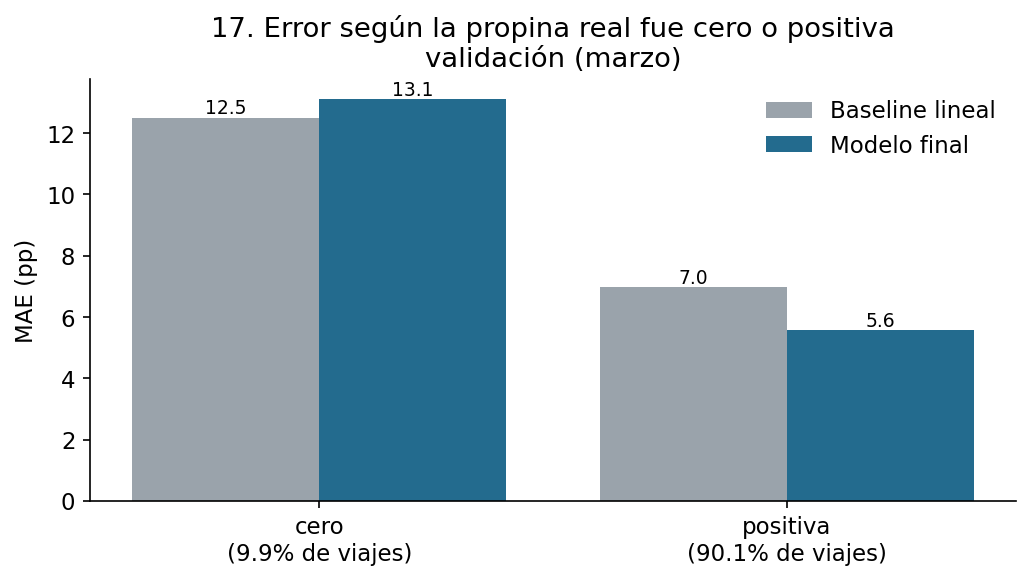

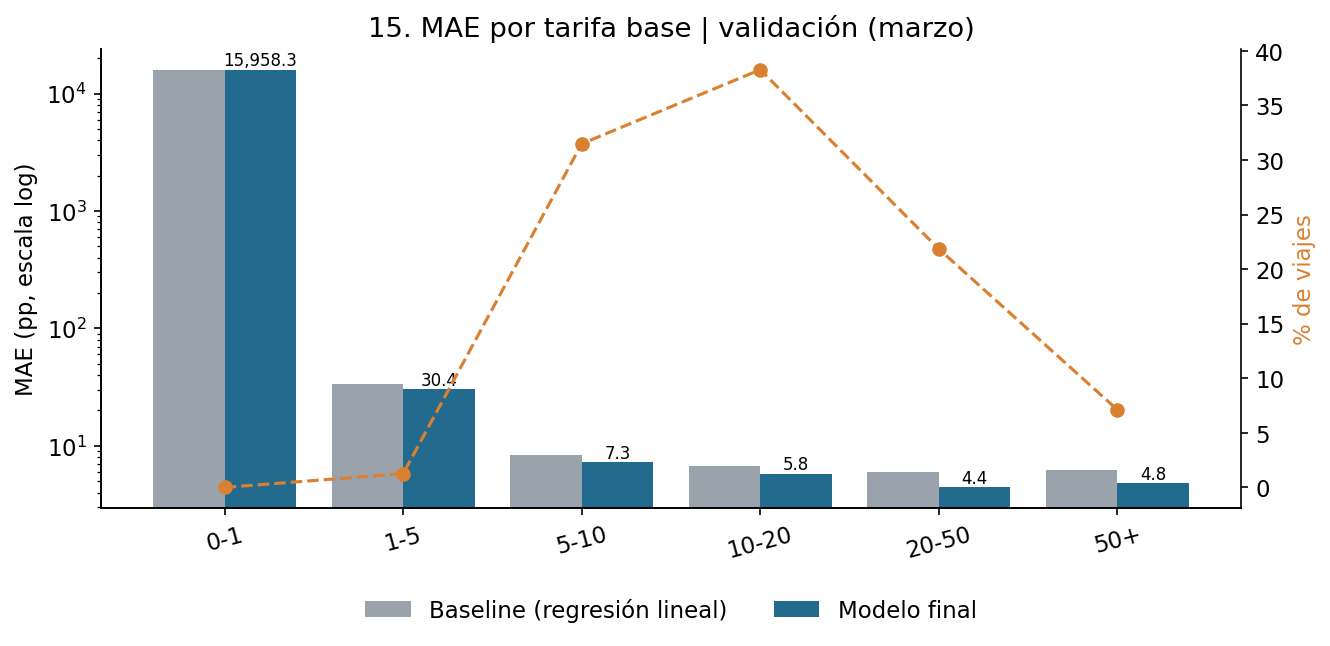

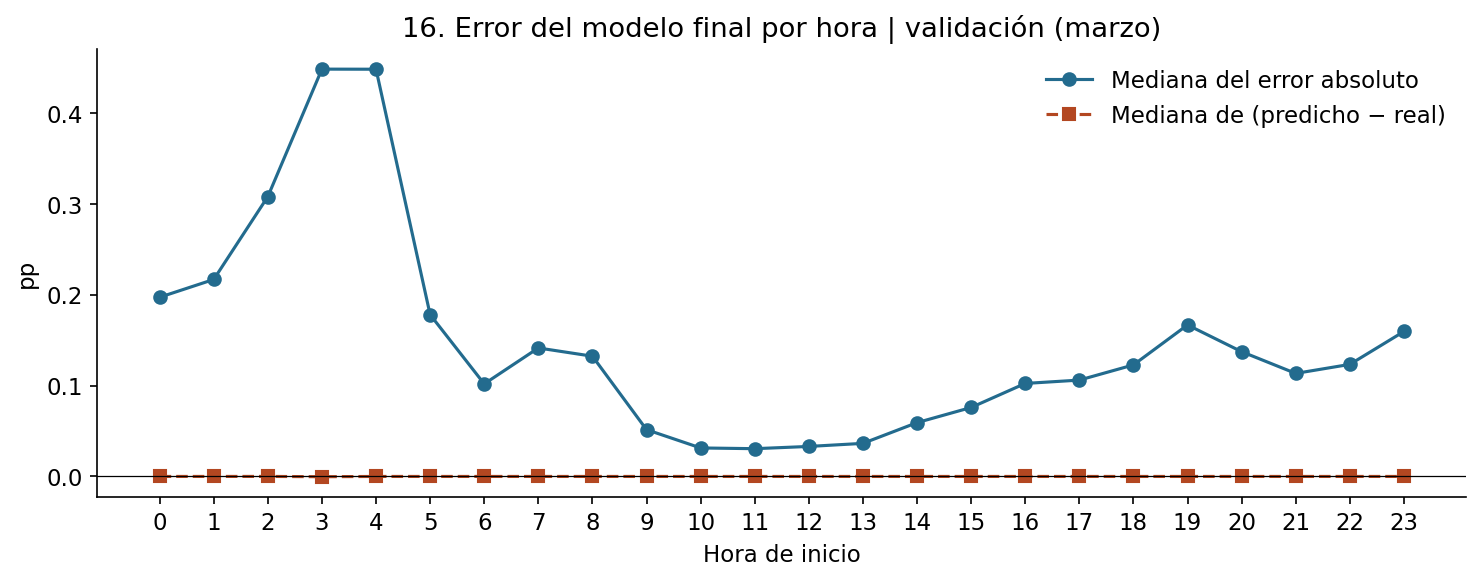

In [6]:
for f in ['17_error_propina_cero.png', '15_mae_por_tarifa.png', '16_error_por_hora.png']:
    display(Image(filename=str(FIG / f)))

### Lectura

1. **Propinas cero (≈10% de marzo).** Es el error dominante: el modelo predice el porcentaje típico y falla por completo cuando el
   pasajero no deja propina; en ese segmento es incluso algo peor que el baseline lineal (que predice valores más bajos). Explica la
   mayor parte del sesgo medio positivo.
2. **Tarifas pequeñas.** Con tarifa menor de USD 5 el denominador amplifica cualquier propina: los 18 viajes con tarifa de hasta USD 1 tienen
   errores de miles de puntos y determinan la RMSE global. No se eliminan de la evaluación.
3. **Viajes cortos y madrugada** tienen más error; aeropuerto y viajes largos, menos (porcentajes más estables).
4. **Registros sospechosos** (1% de los viajes, conservados): su MAE es varias veces el del resto. Marcarlos permite medir este
   costo; eliminarlos habría ocultado el problema.

## 5. Zonas con más error y casos problemáticos

In [7]:
zonas = pd.read_csv(OUT / 'errores_por_zona_validacion.csv')
print('Zonas de inicio con al menos 5 000 viajes en marzo:', len(zonas))
display(zonas.head(10))
display(zonas.tail(5))
casos = pd.read_csv(OUT / 'casos_mayor_error_validacion.csv')
display(casos.head(12))

Zonas de inicio con al menos 5 000 viajes en marzo: 52


,zona_inicio,n,MAE_pp,sesgo_medio_pp,mediana_real_pp,pct_propina_cero
0,148,26305,9.389,2.774,26.021,10.048
1,144,24693,7.468,3.896,26.376,8.014
2,50,12281,7.376,3.371,27.037,10.813
3,79,58492,7.214,4.319,27.037,8.295
4,237,136128,7.191,1.696,28.000,3.251
5,87,12310,7.151,2.622,24.429,11.552
6,137,26903,7.096,3.622,26.800,13.170
7,100,35374,6.966,3.125,27.422,7.995
8,233,25976,6.940,3.308,27.323,7.199
9,48,58669,6.933,2.509,28.099,6.867


,zona_inicio,n,MAE_pp,sesgo_medio_pp,mediana_real_pp,pct_propina_cero
47,166,11235,5.687,1.134,24.520,12.185
48,41,6315,5.676,1.908,11.628,44.355
49,74,5633,5.389,1.929,0.000,51.411
50,70,6722,5.181,1.923,25.991,7.081
51,138,82805,5.097,2.205,26.680,4.172


,tpep_pickup_datetime,fare_amount,trip_distance,duration_min,PULocationID,DOLocationID,RatecodeID,VendorID,tip_percentage,prediccion,error_abs
0,2026-03-20 12:52:38,0.01,0.0,2.000,237,237,5.0,1,140000.000,85.704,139914.296
1,2026-03-26 17:59:32,0.01,0.0,0.950,145,145,5.0,1,80000.000,84.658,79915.342
2,2026-03-29 02:29:25,0.20,0.0,0.133,148,148,5.0,2,44610.000,98.189,44511.811
3,2026-03-08 22:54:43,3.00,0.0,0.117,61,61,1.0,2,13233.333,31.032,13202.301
4,2026-03-14 12:06:19,1.00,0.0,0.083,219,219,5.0,2,9800.000,34.254,9765.746
5,2026-03-29 22:59:06,3.00,0.0,21.883,132,130,1.0,2,9416.667,57.030,9359.636
6,2026-03-17 10:50:12,0.01,0.0,0.233,142,43,5.0,2,8500.000,100.873,8399.127
7,2026-03-10 22:10:36,3.00,0.0,0.200,161,161,1.0,1,6666.667,67.730,6598.937
8,2026-03-23 09:44:35,3.00,3.0,0.183,265,265,1.0,1,3666.667,33.344,3633.322
9,2026-03-01 11:04:00,0.14,0.0,0.217,163,163,5.0,2,3571.429,100.138,3471.291


- El MAE por zona de inicio varía en unos pocos puntos y **no** se explica por la proporción de propinas cero de la zona (la
  correlación es débil). Las zonas de inicio y destino entran por target encoding y su importancia por permutación es baja: el
  modelo no depende fuertemente de la zona.
- Los 25 casos con mayor error tienen tarifas de USD 0.01 a 3 (la mayoría en USD 3) con propinas de varios dólares, varios con
  distancia 0 o duración de segundos y algunos con `RatecodeID = 5` (tarifa negociada). Más que errores del modelo son registros
  en los que la tarifa base no representa el precio real del viaje; por eso no se usa MAPE y se informa la RMSE con tarifa ≥ USD 1.

## 6. Sesgos y uso responsable

- **Medición distinta por proveedor:** el error medio cambia según `VendorID`. Si se usara el modelo para comparar conductores o
  flotas, se confundiría la tecnología del taxímetro con el comportamiento del pasajero.
- **Zonas:** predecir menos propina en ciertas zonas podría inducir a evitar recoger pasajeros allí. El modelo es descriptivo; no
  debe usarse para asignar o negar servicio.
- **Población:** solo tarjeta; las propinas en efectivo no están registradas, así que no se generaliza a todos los pasajeros.

## 7. ¿Se mantienen los patrones en test (abril)?

In [8]:
p = OUT / 'errores_por_segmento_test.csv'
if p.exists():
    seg_test = pd.read_csv(p)
    comp = seg.merge(seg_test, on=['segmento', 'valor'], suffixes=('_marzo', '_abril'))
    display(comp[['segmento', 'valor', 'pct_viajes_abril', 'MAE_pp_marzo', 'MAE_pp_abril', 'mejora_pct_marzo',
                  'mejora_pct_abril']].query("segmento in ['propina real', 'tarifa base (USD)', 'VendorID', 'franja horaria']"))
else:
    print('Aún no se ejecutó la etapa test.')

,segmento,valor,pct_viajes_abril,MAE_pp_marzo,MAE_pp_abril,mejora_pct_marzo,mejora_pct_abril
0,tarifa base (USD),0-1,0.00,15958.327,66022.205,0.0,0.0
1,tarifa base (USD),1-5,1.19,30.450,29.756,9.6,8.6
2,tarifa base (USD),5-10,29.67,7.263,7.217,13.1,12.6
3,tarifa base (USD),10-20,38.63,5.803,5.773,14.6,15.1
4,tarifa base (USD),20-50,23.56,4.425,4.489,26.3,28.6
5,tarifa base (USD),50+,6.94,4.820,4.846,22.6,22.6
12,franja horaria,madrugada (0-5),6.24,8.774,10.323,11.9,10.7
13,franja horaria,mañana pico (6-9),12.45,5.743,5.570,14.0,15.2
14,franja horaria,día (10-15),33.07,5.582,6.775,16.9,15.1
15,franja horaria,tarde pico (16-19),27.24,6.702,6.525,17.5,18.6
